# Day-ahead demand forecasting for ERCOT: a walkthrough

Every morning at 10:00 Central, forecast each hour of tomorrow's Texas demand as a
P10/P50/P90 range. This notebook walks through the parts that make the result
trustworthy, then the results themselves:

1. the data, and what it looks like;
2. the leakage barrier, checked on real data;
3. weather *as it was forecast*, not as it happened;
4. one forecast, end to end, for the record-demand day;
5. the twelve-month backtest, and where the model fails.

Every number comes from the code in `src/`; nothing here is computed differently.

In [1]:
import sys

sys.path.insert(0, '../src')

import pandas as pd
from IPython.display import Image, display

import backtest
import config
import features as F
import metrics as M
import models

pd.set_option('display.width', 140)
frame = pd.read_csv(config.PROCESSED_FILE, index_col=0, parse_dates=True)
first, last = frame.index[0], frame.index[-1]
print(f'{len(frame):,} hours, {first:%Y-%m-%d} to {last:%Y-%m-%d} UTC')
frame.describe().round(1)

46,032 hours, 2021-07-01 to 2026-10-01 UTC


,demand_mw,ercot_da_forecast_mw,temp_c,rh_pct,temp_fc1_c,temp_fc2_c
count,46031.0,45912.0,45830.0,45810.0,10152.0,10152.0
mean,52827.3,53079.9,21.9,66.0,22.6,24.3
std,11584.1,11808.9,8.6,18.4,8.2,7.9
min,29972.0,30316.0,-10.2,10.9,-6.9,-8.5
25%,44147.0,44309.0,16.4,52.3,17.9,19.3
50%,50159.0,50471.0,23.4,68.4,24.3,25.5
75%,59763.0,60130.0,28.0,81.4,28.1,29.7
max,91075.0,92091.0,41.1,100.0,41.0,42.0


## 1. The data

Demand comes from EIA-930, measured weather from five airport stations (NOAA GHCNh)
weighted by city population, and archived GFS weather forecasts from Open-Meteo. The
forecast columns are filled only for the backtest year and its lead-in, because
that is the only place they are used. Demand climbs steeply with heat, which is
most of what there is to predict:

Annual peak demand (GW): {2021: 73.5, 2022: 79.8, 2023: 85.4, 2024: 85.5, 2025: 83.6, 2026: 91.1}


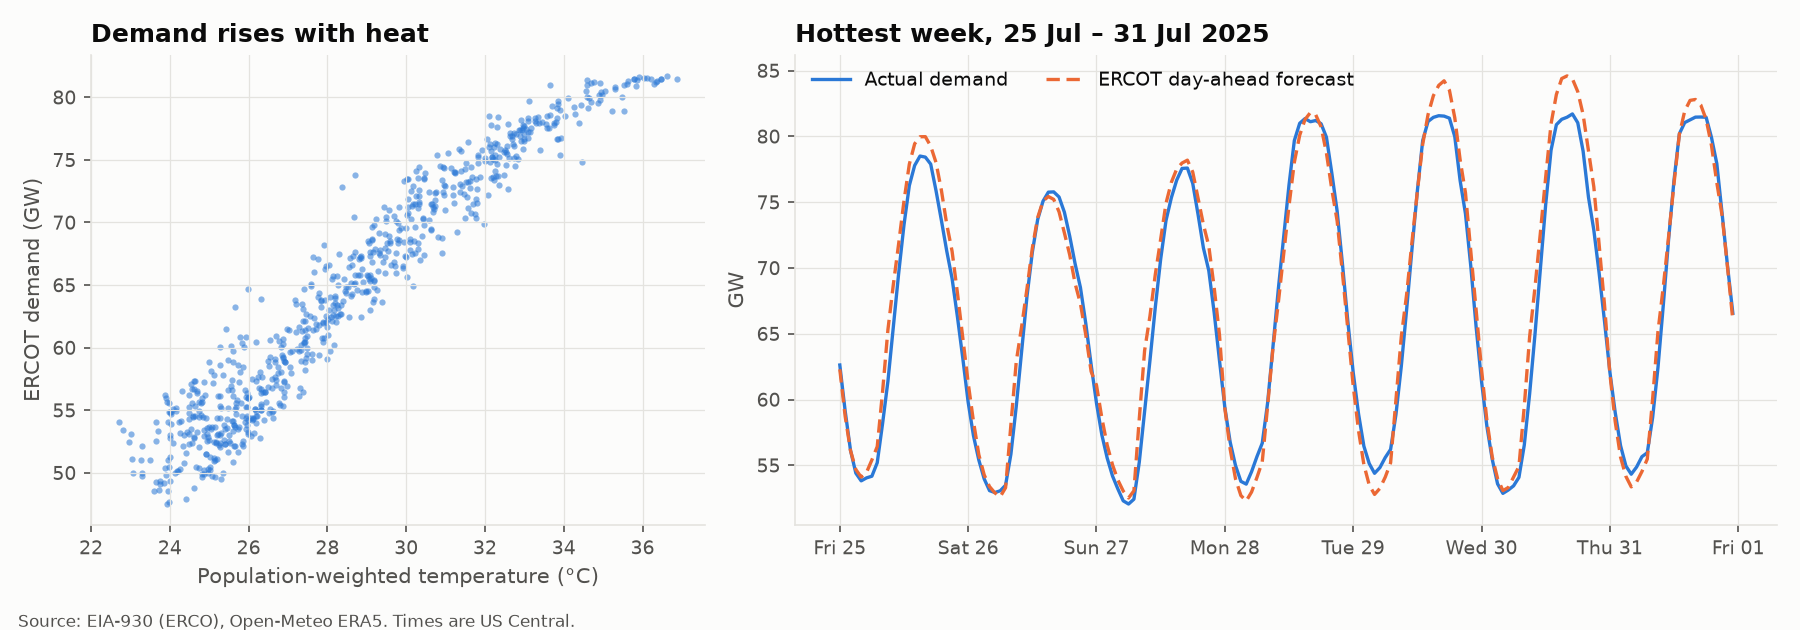

In [2]:
annual_peak = frame['demand_mw'].groupby(frame.index.year).max() / 1e3
print('Annual peak demand (GW):', annual_peak.round(1).to_dict())
display(Image(filename='../reports/figures/sanity_check_2025-07.png'))

The 2026 peak, 91.1 GW, is about 6 GW above anything before it. A model has to be able
to forecast demand it has never seen, which shapes the design in section 4.

## 2. The leakage barrier

Every feature for a forecast issued at 10:00 on day D is built from data strictly
before that moment. The table says where each feature's information comes from:

In [3]:
F.describe_features(F.FeatureSpec(weather='forecast'))

,information source
feature,
lead_hours,hours from issue time to target
demand_lag_48h,"demand at target minus lag, always before issue"
demand_lag_168h,"demand at target minus lag, always before issue"
demand_last_24h_mean,window statistic ending at issue time
demand_last_24h_max,window statistic ending at issue time
demand_last_24h_min,window statistic ending at issue time
demand_last_168h_mean,window statistic ending at issue time
demand_last_168h_max,window statistic ending at issue time
demand_last_168h_min,window statistic ending at issue time


The check that matters: replace everything that was not knowable at the issue time
with noise, and require the features to come out identical. Here it is on the real
data, for the record-demand day, in both weather modes:

In [4]:
issue = F.issue_time_for('2026-07-21')  # forecasts 22 July 2026, the record day
for mode in ('observed', 'forecast'):
    F.assert_no_future_reference(frame, issue, F.FeatureSpec(weather=mode))
    print(f'{mode:>8} weather: features unchanged when the future is noise')

try:
    F.build_features(frame, issue, F.FeatureSpec(lags_hours=(24, 168)))
except ValueError as error:
    print('\nRefused, as it should be:', str(error).split('. ')[0])

observed weather: features unchanged when the future is noise
forecast weather: features unchanged when the future is noise

Refused, as it should be: lag(s) [24] h are not longer than the 37 h lead to the last target hour


"Same hour yesterday" is the most common feature in load forecasting, and at a 10:00
issue time it reads the future for every target hour after 10:00. The guard refuses it.

## 3. Weather as it was forecast

The honest arm uses GFS forecasts archived as they were published, never the weather
that later happened. Forecast and airport readings disagree systematically, so each
forecast is corrected by its own mean error over the 28 days before each issue time:

In [5]:
window = frame.index >= config.BACKTEST_START
rows = []
for column, lead in (('temp_fc1_c', 'day 1 (lead up to 18 h)'),
                     ('temp_fc2_c', 'day 2 (lead over 18 h)')):
    error = (frame[column] - frame['temp_c'])[window]
    rows.append({'forecast': lead, 'mean error (°C)': error.mean(),
                 'MAE (°C)': error.abs().mean()})
pd.DataFrame(rows).set_index('forecast').round(2)

,mean error (°C),MAE (°C)
forecast,,
day 1 (lead up to 18 h),-0.70,1.02
day 2 (lead over 18 h),1.04,1.48


## 4. One forecast, end to end

Train the deliverable model on everything known at 10:00 on 21 July 2026 and forecast
22 July, the day Texas demand hit its record. LightGBM predicts demand *relative to its
4-week level*, so it can go above anything in its training data. The conformal step
calibrates its P10-P90 band on the previous 28 days of forecast-weather errors.

In [6]:
train_spec = F.FeatureSpec(weather='observed')
test_spec = F.FeatureSpec(weather='forecast')
history = F.daily_issue_times(frame, train_spec)
# Issued two or more days earlier: their whole target day was observed by 10:00 today.
X, y = F.build_training_set(frame, history[history <= issue - pd.Timedelta(days=2)],
                            train_spec)
recent = F.daily_issue_times(frame, test_spec,
                             start=issue - pd.Timedelta(days=config.CALIBRATION_DAYS),
                             end=issue - pd.Timedelta(hours=14))
calibration = F.build_training_set(frame, recent, test_spec)

model = models.LightGBMConformal().fit(X, y, calibration=calibration)
forecast = model.predict(F.build_features(frame, issue, test_spec))
forecast['actual'] = frame['demand_mw'].reindex(forecast.index)
peak = forecast['actual'].idxmax()
print(f'Trained on {len(X):,} hours; calibrated on {len(calibration[0]):,}.')
print(f"Peak hour {peak.tz_convert(config.LOCAL_TZ):%H:%M} CDT: actual "
      f"{forecast.loc[peak, 'actual'] / 1e3:.1f} GW, forecast "
      f"{forecast.loc[peak, 'forecast'] / 1e3:.1f} GW, "
      f"P10-P90 {forecast.loc[peak, 'p10'] / 1e3:.1f}"
      f"-{forecast.loc[peak, 'p90'] / 1e3:.1f} GW")
print(f"MAPE over the day: {M.mape(forecast['actual'], forecast['forecast']):.2f}%")

Trained on 43,373 hours; calibrated on 648.
Peak hour 17:00 CDT: actual 91.1 GW, forecast 86.9 GW, P10-P90 82.0-88.9 GW
MAPE over the day: 2.60%


On the hottest day on record the forecast fell short at the peak and the actual broke
above the band. It is a hard day, and the backtest below includes it.

## 5. Twelve months of forecasts

`python src/backtest.py` repeats section 4 for every day from October 2025 to
September 2026, retraining monthly, for every model. These are its results (the honest
arm, with weather forecasts as published):

In [7]:
tables = backtest.tables_from(backtest.load_predictions(), frame, config.BACKTEST_START)
summary = tables['summary']
honest = summary[summary['weather'].isin(['forecast', backtest.NO_WEATHER_ARM])]
honest.set_index('model')[['MAPE_%', 'MASE', 'skill_vs_naive_%', 'peak_mape_%',
                           'coverage_p10_p90_%', 'hours_scored']].round(2)

,MAPE_%,MASE,skill_vs_naive_%,peak_mape_%,coverage_p10_p90_%,hours_scored
model,,,,,,
Seasonal naive (same hour last week),7.42,0.92,0.00,8.55,NaN,8760
ERCOT published day-ahead forecast,2.00,0.25,72.98,2.02,NaN,8640
Vanilla regression (GEFCom benchmark),2.97,0.39,57.57,3.68,NaN,8760
"LightGBM, P10/P50/P90",2.89,0.38,59.29,3.27,43.88,8760
"LightGBM, P10/P50/P90 + conformal",2.94,0.38,58.58,3.27,78.41,8760
"LightGBM, MW target (ablation)",3.70,0.48,47.92,4.17,NaN,8760


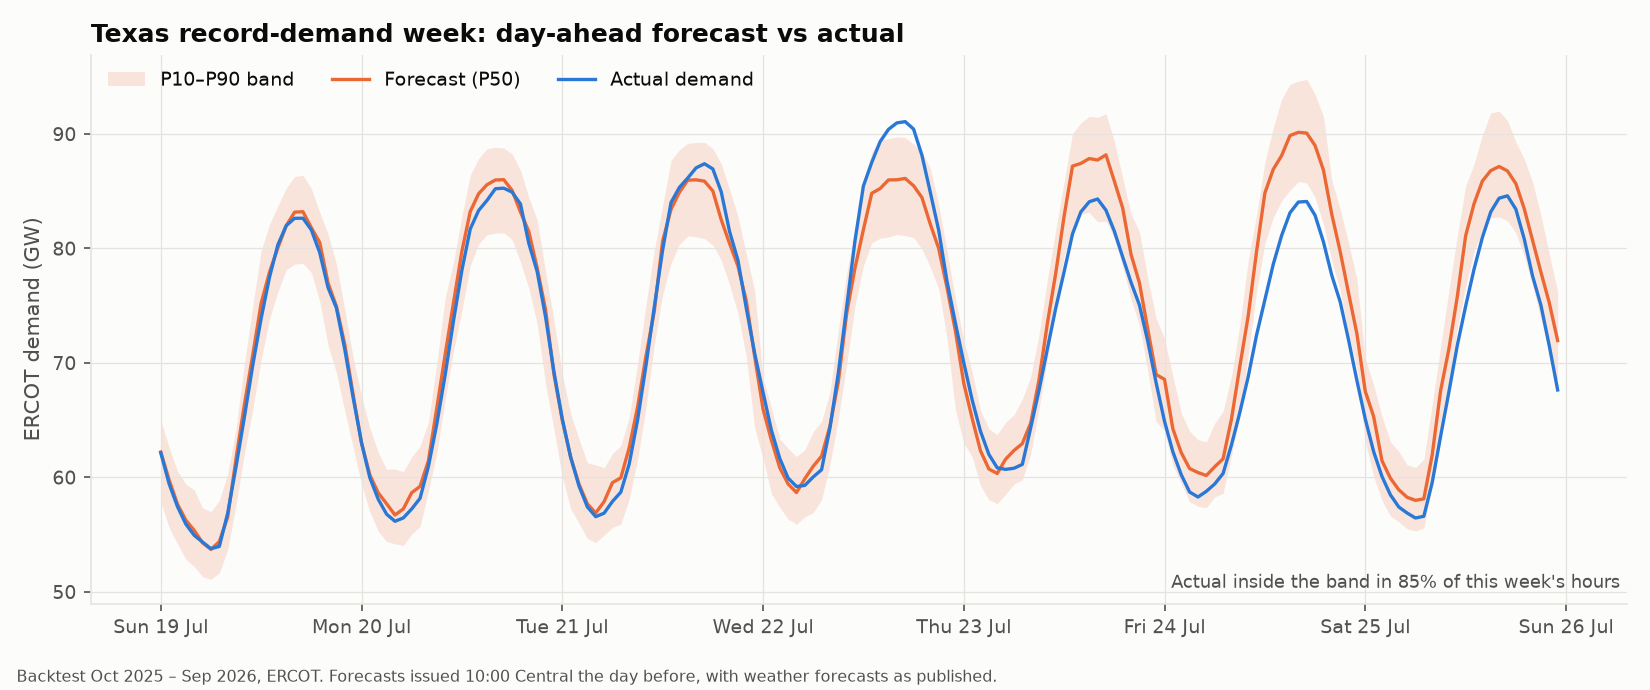

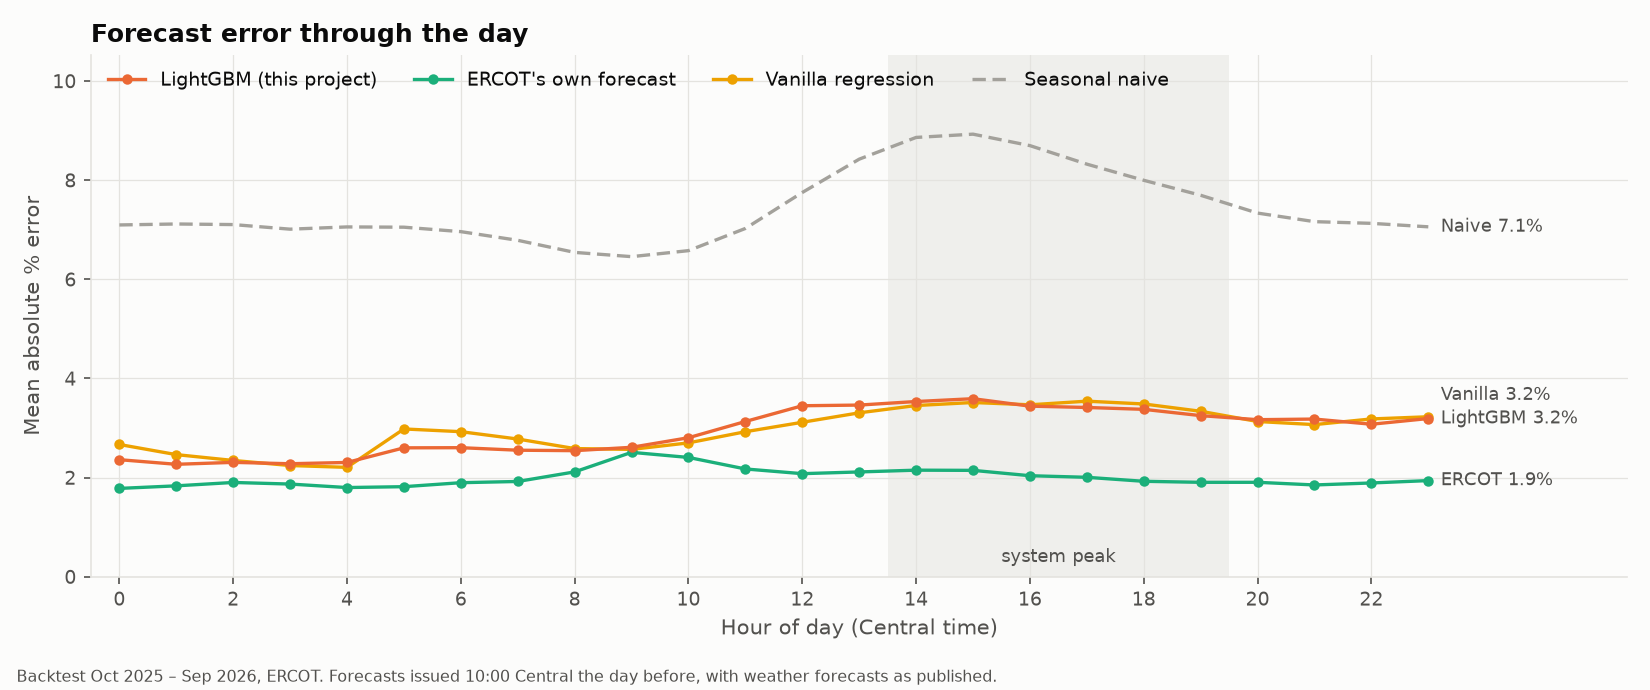

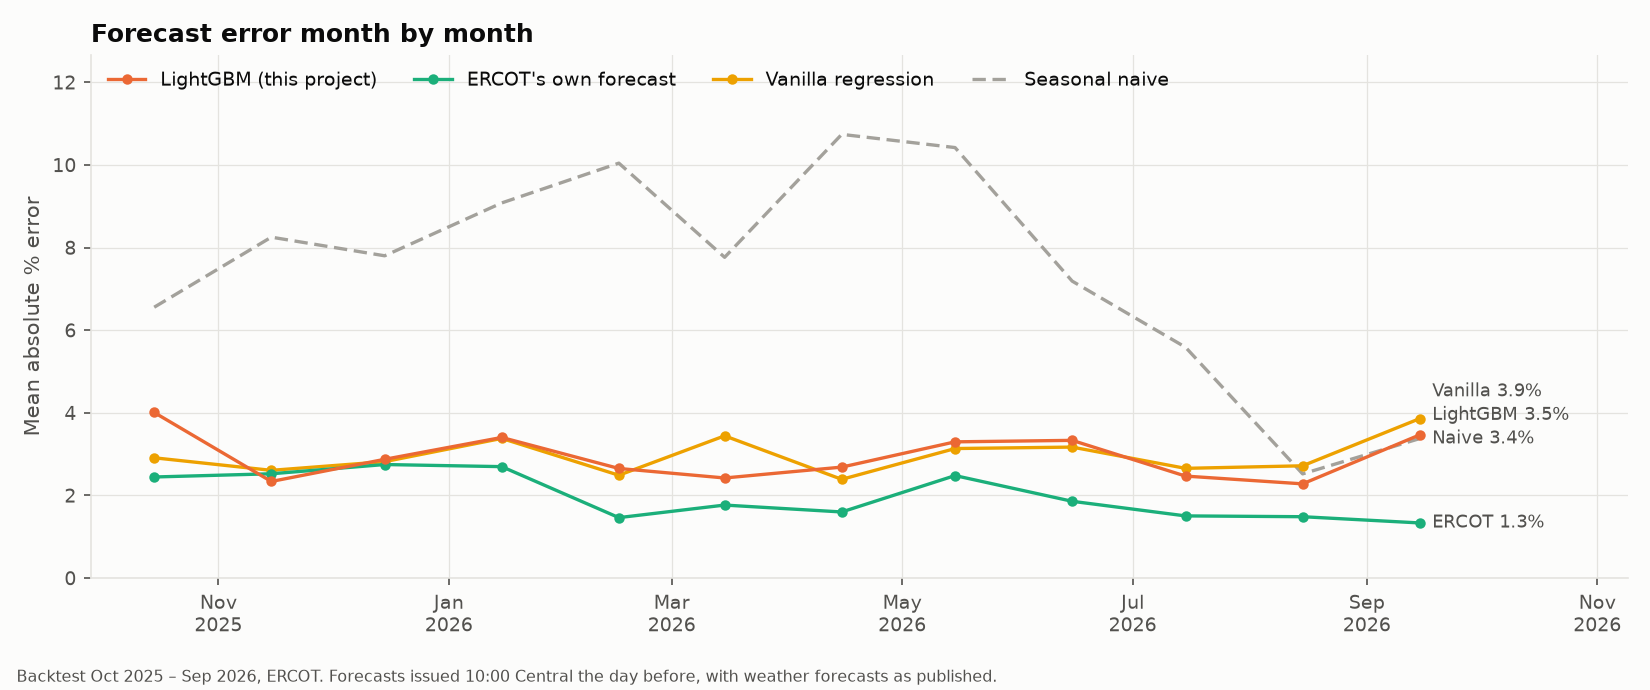

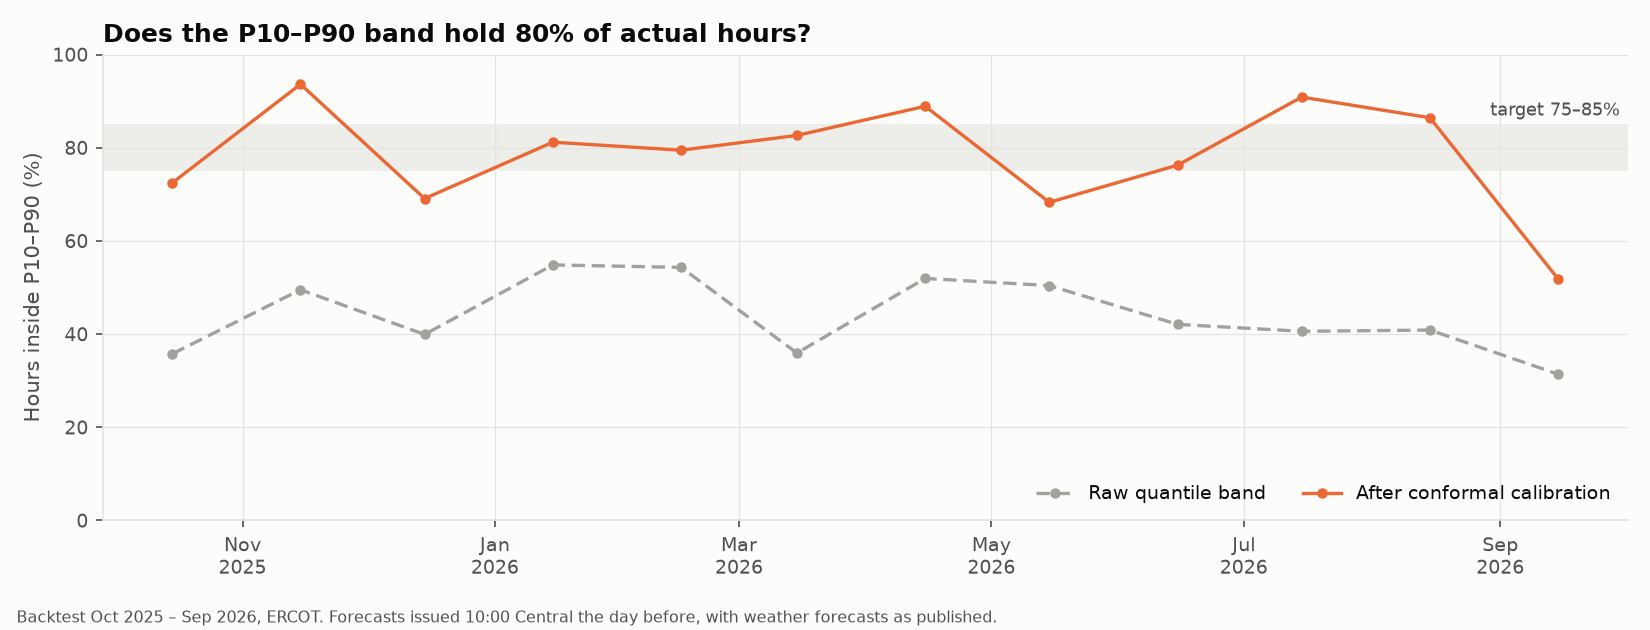

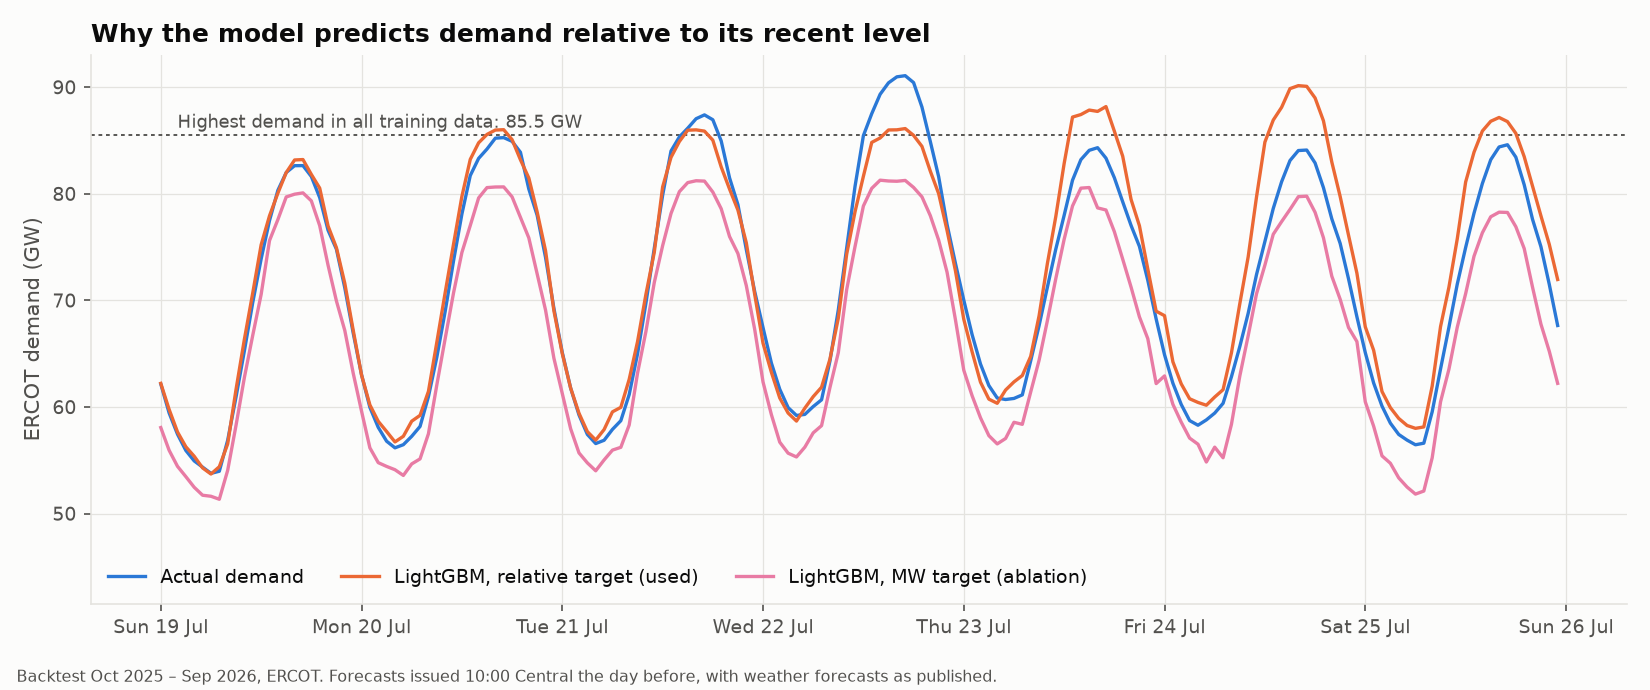

In [8]:
for name in ('record_week_forecast', 'error_by_hour', 'error_by_month',
             'coverage_by_month', 'relative_target_ablation'):
    display(Image(filename=f'../reports/figures/{name}.png'))

## Where it fails

Error by kind of day and by temperature, for the deliverable model and ERCOT. Holidays
are not the weak spot; freezing hours are.

In [9]:
keep = ['LightGBM, P10/P50/P90 + conformal', 'ERCOT published day-ahead forecast',
        'Vanilla regression (GEFCom benchmark)']
for by in ('day_type', 'temp_bin'):
    table = tables[f'breakdown_{by}']
    table = table[table['model'].isin(keep)
                  & table['weather'].isin(['forecast', backtest.NO_WEATHER_ARM])]
    display(table.pivot(index=by, columns='model', values='MAPE_%').round(2))

model,ERCOT published day-ahead forecast,"LightGBM, P10/P50/P90 + conformal",Vanilla regression (GEFCom benchmark)
day_type,,,
day next to a major holiday,1.45,2.50,2.72
major holiday,1.80,2.74,2.90
minor holiday,2.91,2.19,2.85
ordinary weekday,2.00,3.02,3.02
weekend,1.99,2.87,2.89


model,ERCOT published day-ahead forecast,"LightGBM, P10/P50/P90 + conformal",Vanilla regression (GEFCom benchmark)
temp_bin,,,
< 0,3.83,6.25,6.39
0-10,3.17,3.09,3.55
10-20,2.12,2.73,2.12
20-25,2.05,2.73,2.67
25-30,1.76,3.09,3.48
30-35,1.43,3.26,3.33
≥ 35,1.47,1.84,2.61


## What this adds up to

- The model cuts the seasonal-naive error by 59%, to 2.9% MAPE.
- It beats the classical regression benchmark only narrowly.
- It does not beat ERCOT's own forecast (2.0%).
- Predicting relative demand is what kept it accurate through a record summer.
- The calibrated band holds 78% of hours over the year, with real month-to-month swings.

Limitations and the full analysis: `README.md` and `docs/analysis.md`.